In [1]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import zipfile, shutil, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

print(torch.__version__, torch.cuda.is_available())

2.14.0+cu130 True


In [2]:
BASE = Path.cwd()
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

zips = list(BASE.glob('*.zip'))
if not (BASE / 'train').exists() and zips:
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(BASE)

def find_dir(name):
    if (BASE / name).is_dir():
        return BASE / name
    for p in BASE.rglob(name):
        if p.is_dir() and not {'yolo_data', 'runs', '.venv'} & set(p.parts):
            return p

def list_images(d):
    return sorted(p for p in d.rglob('*') if p.suffix.lower() in IMG_EXT)

TRAIN_DIR = find_dir('train')
TEST_DIR = find_dir('test')
train_imgs = list_images(TRAIN_DIR)
test_imgs = list_images(TEST_DIR)
SAMPLE_PATH = next(BASE.rglob('sample_sub*.csv'))

print(TRAIN_DIR, len(train_imgs))
print(TEST_DIR, len(test_imgs))
print(SAMPLE_PATH)

/data/Desktop/ml_10-06/42-CarsObjectDetection/train 234
/data/Desktop/ml_10-06/42-CarsObjectDetection/test 59
/data/Desktop/ml_10-06/42-CarsObjectDetection/sample_submission.csv


In [3]:
from PIL import Image

LABEL_DIR = next(p for p in TRAIN_DIR.rglob('labels') if p.is_dir())
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import zipfile, shutil, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

print(torch.__version__, torch.cuda.is_available())
def read_labels(img_path):
    p = LABEL_DIR / f'{img_path.stem}.txt'
    if not p.exists() or p.stat().st_size == 0:
        return np.zeros((0, 5), dtype=np.float32)
    return np.loadtxt(p, ndmin=2, dtype=np.float32)[:, :5]

def labels_to_xyxy(lab, w, h):
    cx, cy, bw, bh = lab[:, 1] * w, lab[:, 2] * h, lab[:, 3] * w, lab[:, 4] * h
    return np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1)

rows = []
for p in train_imgs:
    w, h = Image.open(p).size
    for c, cx, cy, bw, bh in read_labels(p):
        rows.append([p.name, w, h, bw * w, bh * h])
df = pd.DataFrame(rows, columns=['image', 'img_w', 'img_h', 'box_w', 'box_h'])

print(LABEL_DIR)
print('Фото:', len(train_imgs), '| с разметкой:', df['image'].nunique(), '| всего машин:', len(df))
print(df[['img_w', 'img_h']].value_counts())
print(df.groupby('image').size().describe())
df[['box_w', 'box_h']].describe(percentiles=[.01, .05, .25, .5, .75, .95])

2.14.0+cu130 True
/data/Desktop/ml_10-06/42-CarsObjectDetection/train/train/labels
Фото: 234 | с разметкой: 234 | всего машин: 9294
img_w  img_h
4000   3000     9294
Name: count, dtype: int64
count    234.000000
mean      39.717949
std       32.061327
min        1.000000
25%       16.250000
50%       32.000000
75%       52.000000
max      214.000000
dtype: float64


,box_w,box_h
count,9294.000000,9294.000000
mean,224.853210,192.744400
std,191.580017,195.969421
min,3.020898,0.335655
1%,25.997606,19.625739
5%,40.622531,28.349058
25%,86.273399,60.000000
50%,158.611305,115.367584
75%,307.248108,250.935673
95%,631.578918,635.006067


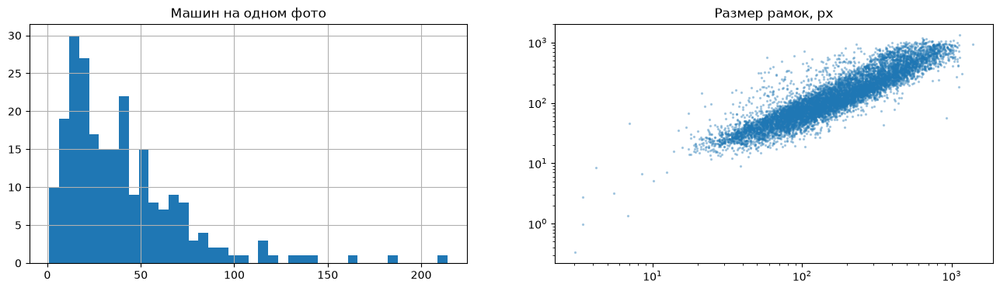

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
df.groupby('image').size().hist(bins=40, ax=axes[0])
axes[0].set_title('Машин на одном фото')
axes[1].scatter(df['box_w'], df['box_h'], s=2, alpha=0.3)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Размер рамок, px')
plt.show()

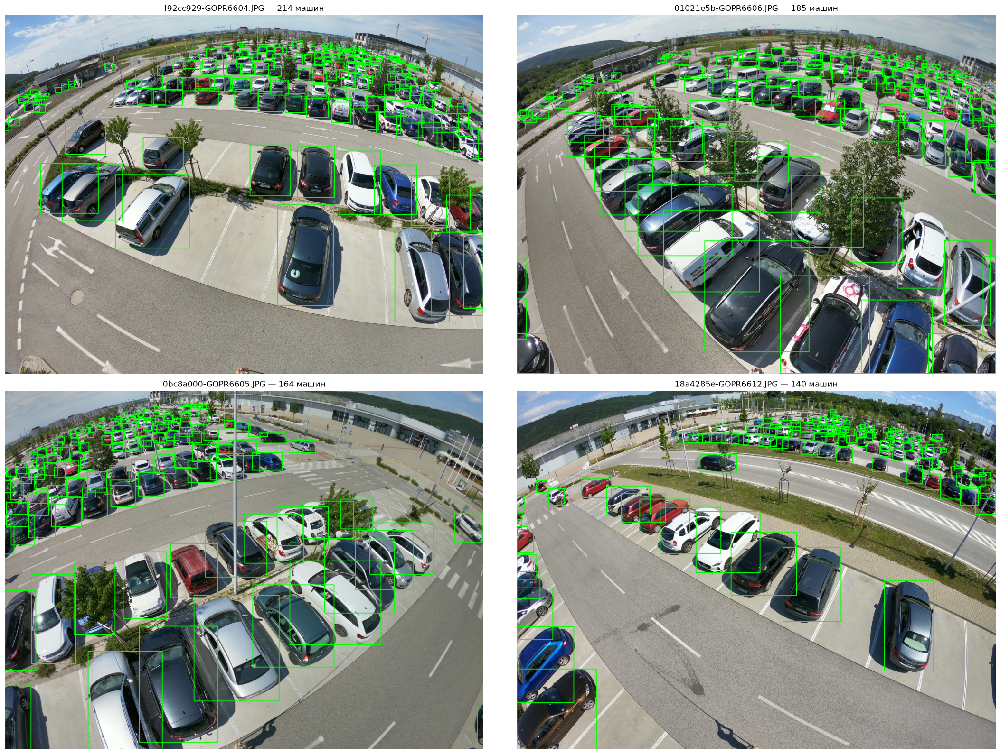

In [5]:
name2path = {p.name: p for p in train_imgs}
top = df.groupby('image').size().sort_values(ascending=False).index[:4]

fig, axes = plt.subplots(2, 2, figsize=(22, 16))
for ax, name in zip(axes.ravel(), top):
    p = name2path[name]
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    boxes = labels_to_xyxy(read_labels(p), w, h).astype(int)
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 6)
    ax.imshow(img)
    ax.set_title(f'{name} — {len(boxes)} машин')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
SCALE = 0.5
TILE = 640
OVERLAP = 0.25
MIN_VIS = 0.4
VAL_FRAC = 0.15
YOLO_DIR = BASE / 'yolo_data'

def tile_starts(size, tile, overlap):
    if size <= tile:
        return [0]
    stride = int(tile * (1 - overlap))
    s = list(range(0, size - tile + 1, stride))
    if s[-1] + tile < size:
        s.append(size - tile)
    return s

def write_sample(img, boxes, out_img, out_lab):
    h, w = img.shape[:2]
    cv2.imwrite(str(out_img), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    lines = [f'0 {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}'
             for x1, y1, x2, y2 in boxes if x2 - x1 >= 2 and y2 - y1 >= 2]
    out_lab.write_text('\n'.join(lines))

def build_split(imgs, split):
    img_dir = YOLO_DIR / 'images' / split
    lab_dir = YOLO_DIR / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lab_dir.mkdir(parents=True, exist_ok=True)
    n = 0
    for p in imgs:
        img = cv2.resize(cv2.imread(str(p)), None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)
        h, w = img.shape[:2]
        boxes = labels_to_xyxy(read_labels(p), w, h)
        areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        for y0 in tile_starts(h, TILE, OVERLAP):
            for x0 in tile_starts(w, TILE, OVERLAP):
                crop = img[y0:y0 + TILE, x0:x0 + TILE]
                ch, cw = crop.shape[:2]
                b = boxes.copy()
                b[:, [0, 2]] = np.clip(b[:, [0, 2]] - x0, 0, cw)
                b[:, [1, 3]] = np.clip(b[:, [1, 3]] - y0, 0, ch)
                bw, bh = b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]
                keep = (bw >= 3) & (bh >= 3) & (bw * bh >= MIN_VIS * areas)
                write_sample(crop, b[keep], img_dir / f'{p.stem}_{x0}_{y0}.jpg', lab_dir / f'{p.stem}_{x0}_{y0}.txt')
                n += 1
        k = TILE / max(h, w)
        full = cv2.resize(img, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
        write_sample(full, boxes * k, img_dir / f'{p.stem}_full.jpg', lab_dir / f'{p.stem}_full.txt')
        n += 1
    return n

if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)

random.seed(42)
imgs = train_imgs.copy()
random.shuffle(imgs)
n_val = round(len(imgs) * VAL_FRAC)
val_imgs, tr_imgs = imgs[:n_val], imgs[n_val:]

print('train фото:', len(tr_imgs), '-> тайлов:', build_split(tr_imgs, 'train'))
print('val фото:', len(val_imgs), '-> тайлов:', build_split(val_imgs, 'val'))

DATA_YAML = YOLO_DIR / 'data.yaml'
DATA_YAML.write_text(f"path: {YOLO_DIR.as_posix()}\ntrain: images/train\nval: images/val\nnames:\n  0: car\n")
print(DATA_YAML.read_text())

train фото: 199 -> тайлов: 2587
val фото: 35 -> тайлов: 455
path: /data/Desktop/ml_10-06/42-CarsObjectDetection/yolo_data
train: images/train
val: images/val
names:
  0: car



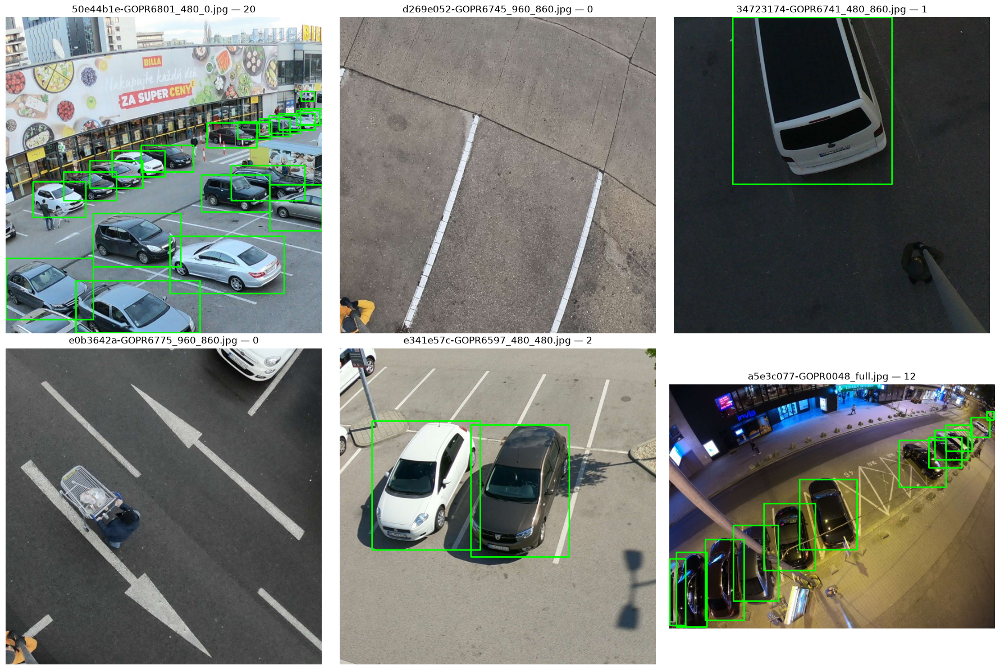

In [7]:
tiles = sorted((YOLO_DIR / 'images' / 'train').glob('*.jpg'))
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, t in zip(axes.ravel(), random.sample(tiles, 6)):
    img = cv2.cvtColor(cv2.imread(str(t)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lab_path = YOLO_DIR / 'labels' / 'train' / f'{t.stem}.txt'
    lab = np.loadtxt(lab_path, ndmin=2) if lab_path.stat().st_size else np.zeros((0, 5))
    for x1, y1, x2, y2 in labels_to_xyxy(lab, w, h).astype(int):
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    ax.imshow(img)
    ax.set_title(f'{t.name} — {len(lab)}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
import psutil

GPU = torch.cuda.is_available()
VRAM = torch.cuda.get_device_properties(0).total_memory / 1e9 if GPU else 0
RAM = psutil.virtual_memory().total / 1e9
CPU = os.cpu_count()

if VRAM >= 10:
    MODEL_NAME = 'yolo26m.pt'
elif VRAM >= 3:
    MODEL_NAME = 'yolo26s.pt'
else:
    MODEL_NAME = 'yolo26n.pt'

BATCH = 2
WORKERS = max(2, min(8, CPU // 2, int(RAM // 4)))

print(torch.cuda.get_device_name(0) if GPU else 'CPU')
print(f'VRAM: {VRAM:.1f} GB | RAM: {RAM:.1f} GB | CPU: {CPU}')
print(f'Модель: {MODEL_NAME} | batch: {BATCH} | workers: {WORKERS}')

HYP = dict(
    data=str(DATA_YAML),
    epochs=80,
    patience=20,
    imgsz=TILE,
    batch=BATCH,
    nbs=64,
    device=0 if GPU else 'cpu',
    workers=WORKERS,
    optimizer='AdamW',
    lr0=0.001,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3,
    cos_lr=True,
    amp=False,
    cache=False,
    hsv_h=0.015,
    hsv_s=0.6,
    hsv_v=0.4,
    degrees=0.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    mosaic=1.0,
    mixup=0.0,
    close_mosaic=10,
    seed=42,
    deterministic=False,
    plots=True,
    project=str(BASE / 'runs'),
    name='cars_yolo26_tiles',
    exist_ok=True,
)
HYP

NVIDIA GeForce GTX 1650 Ti
VRAM: 3.9 GB | RAM: 32.9 GB | CPU: 12
Модель: yolo26s.pt | batch: 2 | workers: 6


{'data': '/data/Desktop/ml_10-06/42-CarsObjectDetection/yolo_data/data.yaml',
 'epochs': 80,
 'patience': 20,
 'imgsz': 640,
 'batch': 2,
 'nbs': 64,
 'device': 0,
 'workers': 6,
 'optimizer': 'AdamW',
 'lr0': 0.001,
 'lrf': 0.01,
 'momentum': 0.937,
 'weight_decay': 0.0005,
 'warmup_epochs': 3,
 'cos_lr': True,
 'amp': False,
 'cache': False,
 'hsv_h': 0.015,
 'hsv_s': 0.6,
 'hsv_v': 0.4,
 'degrees': 0.0,
 'translate': 0.1,
 'scale': 0.5,
 'fliplr': 0.5,
 'flipud': 0.0,
 'mosaic': 1.0,
 'mixup': 0.0,
 'close_mosaic': 10,
 'seed': 42,
 'deterministic': False,
 'plots': True,
 'project': '/data/Desktop/ml_10-06/42-CarsObjectDetection/runs',
 'name': 'cars_yolo26_tiles',
 'exist_ok': True}

In [9]:
model = YOLO(MODEL_NAME)
model.info()

YOLO26s summary: 260 layers, 10,009,784 parameters, 0 gradients, 23.1 GFLOPs


(260, 10009784, 0, 23.0793216)

In [10]:
results = model.train(**HYP)
SAVE_DIR = Path(model.trainer.save_dir)
BEST_PATH = SAVE_DIR / 'weights' / 'best.pt'
print(BEST_PATH)

Ultralytics 8.4.155 🚀 Python-3.11.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 3715MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/data/Desktop/ml_10-06/42-CarsObjectDetection/yolo_data/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

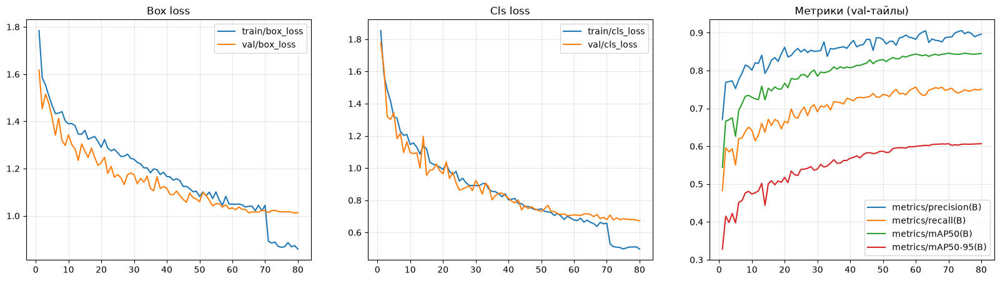

In [14]:
res = pd.read_csv(SAVE_DIR / 'results.csv')
res.columns = [c.strip() for c in res.columns]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for col in ['train/box_loss', 'val/box_loss']:
    axes[0].plot(res['epoch'], res[col], label=col)
for col in ['train/cls_loss', 'val/cls_loss']:
    axes[1].plot(res['epoch'], res[col], label=col)
for col in ['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    axes[2].plot(res['epoch'], res[col], label=col)
for ax, t in zip(axes, ['Box loss', 'Cls loss', 'Метрики (val-тайлы)']):
    ax.set_title(t)
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

In [15]:
best_model = YOLO(str(BEST_PATH))
metrics = best_model.val(data=str(DATA_YAML), imgsz=TILE, split='val', batch=4)
print(f'Precision: {metrics.box.mp:.4f}')
print(f'Recall:    {metrics.box.mr:.4f}')
print(f'mAP50:     {metrics.box.map50:.4f}')
print(f'mAP50-95:  {metrics.box.map:.4f}')

Ultralytics 8.4.155 🚀 Python-3.11.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 3715MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3881.9±1304.2 MB/s, size: 159.3 KB)
val: Scanning /data/Desktop/ml_10-06/42-CarsObjectDetection/yolo_data/labels/val.cache... 455 images, 116 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 455/455 238.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 114/114 13.0it/s 8.7s0.2s
                   all        455       3601      0.897       0.75      0.845      0.607
Speed: 0.6ms preprocess, 15.9ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /data/Desktop/ml_10-06/42-CarsObjectDetection/runs/detect/val-2
Precision: 0.8974
Recall:    0.7501
mAP50:     0.8454
mAP50-95:  0.6066


In [26]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

sahi_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path=str(BEST_PATH),
    confidence_threshold=0.01,
    device='cuda:0' if GPU else 'cpu',
    image_size=TILE,
)

PP = dict(postprocess_type='NMS', postprocess_match_metric='IOS', postprocess_match_threshold=0.6)
TARGET_SIDE = 4000 * SCALE

def predict_sahi(source, pp=None):
    img = cv2.imread(str(source))
    if img is None:
        raise FileNotFoundError(f'Не удалось открыть файл: {source}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    k = TARGET_SIDE / max(img.shape[:2])
    small = cv2.resize(img, None, fx=k, fy=k, interpolation=cv2.INTER_AREA if k < 1 else cv2.INTER_CUBIC)
    res = get_sliced_prediction(
        small, sahi_model,
        slice_height=TILE, slice_width=TILE,
        overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP,
        perform_standard_pred=True, batch_size=4, verbose=0,
        **(pp or PP),
    )
    boxes = np.array([o.bbox.to_xyxy() for o in res.object_prediction_list], dtype=np.float32).reshape(-1, 4) / k
    scores = np.array([o.score.value for o in res.object_prediction_list], dtype=np.float32)
    return img, boxes, scores

In [27]:
def iou_matrix(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def match(preds, gts, thr):
    tps, confs, n_gt = [], [], 0
    for k, g in gts.items():
        p, s = preds[k]
        n_gt += len(g)
        order = np.argsort(-s)
        p, s = p[order], s[order]
        tp = np.zeros(len(p))
        if len(p) and len(g):
            ious = iou_matrix(p, g)
            used = np.zeros(len(g), bool)
            for i in range(len(p)):
                cand = np.where(used, -1, ious[i])
                j = cand.argmax()
                if cand[j] >= thr:
                    tp[i] = 1
                    used[j] = True
        tps.append(tp)
        confs.append(s)
    tp, conf = np.concatenate(tps), np.concatenate(confs)
    order = np.argsort(-conf)
    return tp[order], conf[order], n_gt

def average_precision(tp, n_gt):
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / max(n_gt, 1)
    prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.concatenate([[0], rec, [1]])
    mpre = np.flip(np.maximum.accumulate(np.flip(np.concatenate([[1], prec, [0]]))))
    return np.mean(np.interp(np.linspace(0, 1, 101), mrec, mpre))

def evaluate(preds, gts):
    tp, conf, n_gt = match(preds, gts, 0.5)
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    f1 = 2 * ctp / (ctp + cfp + n_gt + 1e-9)
    i = f1.argmax()
    map5095 = np.mean([average_precision(match(preds, gts, t)[0], n_gt) for t in np.arange(0.5, 0.96, 0.05)])
    return dict(mAP50=average_precision(tp, n_gt), mAP50_95=map5095, best_F1=f1[i], best_conf=conf[i])

val_gt = {p.name: labels_to_xyxy(read_labels(p), *Image.open(p).size) for p in val_imgs}

configs = {
    'SAHI NMS-IOS-0.6': dict(postprocess_type='NMS', postprocess_match_metric='IOS', postprocess_match_threshold=0.6),
    'SAHI NMS-IOU-0.5': dict(postprocess_type='NMS', postprocess_match_metric='IOU', postprocess_match_threshold=0.5),
    'SAHI GREEDYNMM-IOS-0.5': dict(postprocess_type='GREEDYNMM', postprocess_match_metric='IOS', postprocess_match_threshold=0.5),
}

report = {}
base_preds = {}
for p in val_imgs:
    r = best_model.predict(str(p), imgsz=TILE, conf=0.01, max_det=1000, verbose=False)[0]
    base_preds[p.name] = (r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())
report['YOLO целый кадр'] = evaluate(base_preds, val_gt)

for name, pp in configs.items():
    preds = {}
    for p in val_imgs:
        _, b, s = predict_sahi(p, pp)
        preds[p.name] = (b, s)
    report[name] = evaluate(preds, val_gt)

report = pd.DataFrame(report).T
print(report)

best_name = report.loc[list(configs)].sort_values('mAP50_95', ascending=False).index[0]
PP = configs[best_name]
VIS_CONF = float(report.loc[best_name, 'best_conf'])
print('Лучший вариант:', best_name, '| порог для отрисовки:', round(VIS_CONF, 3))

2026-09-19 13:20:19,807 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:20,121 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:20,417 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:20,735 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:21,043 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:21,357 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-09-19 13:20:21,663 - sahi - WARNING - Switching postprocess type/metric to NM

                           mAP50  mAP50_95   best_F1  best_conf
YOLO целый кадр         0.756459  0.513144  0.733545   0.285066
SAHI NMS-IOS-0.6        0.858017  0.613043  0.844112   0.315810
SAHI NMS-IOU-0.5        0.817475  0.576588  0.780920   0.404052
SAHI GREEDYNMM-IOS-0.5  0.817475  0.576588  0.780920   0.404052
Лучший вариант: SAHI NMS-IOS-0.6 | порог для отрисовки: 0.316


In [28]:
import json

EXPORT_DIR = BASE / 'saved_model'
EXPORT_DIR.mkdir(exist_ok=True)

shutil.copy(BEST_PATH, EXPORT_DIR / 'cars_yolo26s_best.pt')

config = dict(
    model_file='cars_yolo26s_best.pt',
    base_model=MODEL_NAME,
    scale=SCALE,
    tile=TILE,
    overlap=OVERLAP,
    postprocess=PP,
    vis_conf=VIS_CONF,
    val_metrics=report.loc[best_name].to_dict(),
)
(EXPORT_DIR / 'config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False))

print(EXPORT_DIR)
print(json.dumps(config, indent=2, ensure_ascii=False))

/data/Desktop/ml_10-06/42-CarsObjectDetection/saved_model
{
  "model_file": "cars_yolo26s_best.pt",
  "base_model": "yolo26s.pt",
  "scale": 0.5,
  "tile": 640,
  "overlap": 0.25,
  "postprocess": {
    "postprocess_type": "NMS",
    "postprocess_match_metric": "IOS",
    "postprocess_match_threshold": 0.6
  },
  "vis_conf": 0.3158101439476013,
  "val_metrics": {
    "mAP50": 0.8580170787416141,
    "mAP50_95": 0.6130429281495735,
    "best_F1": 0.8441121495323948,
    "best_conf": 0.3158101439476013
  }
}


In [29]:
def detect_cars(source, conf=None, figsize=(22, 16)):
    conf = VIS_CONF if conf is None else conf
    img, boxes, scores = predict_sahi(source)
    keep = scores >= conf
    boxes, scores = boxes[keep], scores[keep]
    vis = img.copy()
    t = max(2, vis.shape[1] // 800)
    for (x1, y1, x2, y2), s in zip(boxes.astype(int), scores):
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), t)
        cv2.putText(vis, f'{s:.2f}', (x1, max(y1 - 5, 20)), cv2.FONT_HERSHEY_SIMPLEX, t * 0.35, (255, 255, 0), t)
    plt.figure(figsize=figsize)
    plt.imshow(vis)
    plt.title(f'{Path(str(source)).name} — найдено машин: {len(boxes)}', fontsize=16)
    plt.axis('off')
    plt.show()
    return pd.DataFrame(boxes, columns=['xmin', 'ymin', 'xmax', 'ymax']).assign(conf=scores)

In [30]:
for i, p in enumerate(test_imgs):
    print(i, p.name)

0 024cfeb7-GOPR6549.JPG
1 0635aa25-GOPR6590.JPG
2 06a132db-GOPR6571.JPG
3 0758bd59-GOPR6699.JPG
4 0e8671d1-GOPR6626.JPG
5 138396e0-GOPR6738.JPG
6 15498cfb-GOPR6614.JPG
7 19dec389-GOPR0037.JPG
8 1cf3c7af-GOPR6787.JPG
9 1f116d33-GOPR6753.JPG
10 1fe18e90-GOPR6611.JPG
11 1ffbb9fb-GOPR6788.JPG
12 204f5fff-GOPR6799.JPG
13 22e8c404-GOPR6769.JPG
14 2a694f42-GOPR6594.JPG
15 2d642a0c-GOPR6677.JPG
16 399bc6ff-GOPR0045.JPG
17 3bfcab70-GOPR6638.JPG
18 3ee1ee02-GOPR6568.JPG
19 450f16e2-GOPR6777.JPG
20 4540bdc9-GOPR6548.JPG
21 483b2b68-GOPR6740.JPG
22 50990abb-GOPR6713.JPG
23 5650d253-GOPR6579.JPG
24 5f4cc069-GOPR6650.JPG
25 670f9c60-GOPR6696.JPG
26 6a0b2803-GOPR6697.JPG
27 6fca18c8-GOPR6592.JPG
28 71596657-GOPR6691.JPG
29 76b4a0fa-GOPR6705.JPG
30 77786278-GOPR0093.JPG
31 78d0ace2-GOPR6655.JPG
32 7e8035e8-GOPR6689.JPG
33 835d5a53-GOPR6555.JPG
34 838f982d-GOPR6551.JPG
35 8602ce67-GOPR6687.JPG
36 8f3c7e90-GOPR0094.JPG
37 92d657c4-GOPR6545.JPG
38 97518b51-GOPR6618.JPG
39 99810d6b-GOPR6607.JPG
40 9c4523b

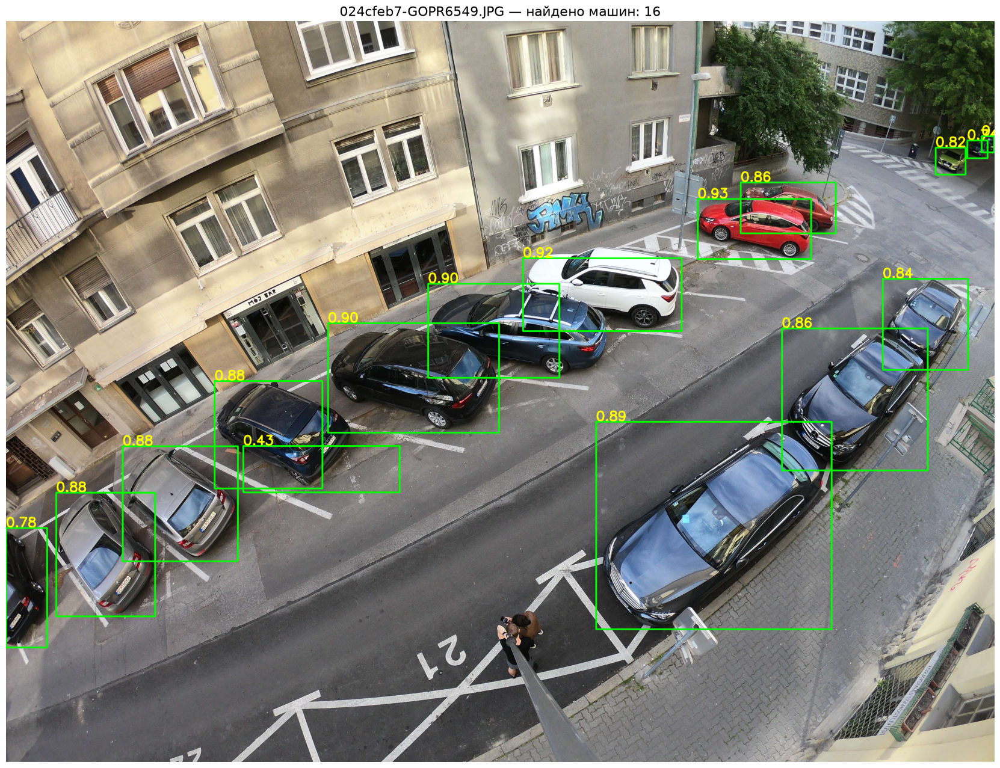

,xmin,ymin,xmax,ymax,conf
0,2799.320312,720.147339,3258.287598,963.859863,0.925676
1,2092.980225,960.000000,2734.924561,1255.791748,0.918682
2,1708.076050,1063.222412,2239.859375,1444.098389,0.901524
3,1303.981812,1223.511108,1995.526978,1666.524170,0.897280
4,2388.388916,1622.544067,3341.270508,2462.950928,0.885815
5,844.152222,1457.022705,1280.000000,1892.322510,0.882332
6,203.079041,1909.198242,603.359924,2410.771484,0.880234
7,472.761383,1721.976562,938.027466,2187.790527,0.878342
8,3140.545654,1244.080566,3730.236084,1819.782593,0.864196
9,2973.859375,653.041626,3358.041992,859.972168,0.863399


In [31]:
TEST_IMAGE = test_imgs[0]
detect_cars(TEST_IMAGE)

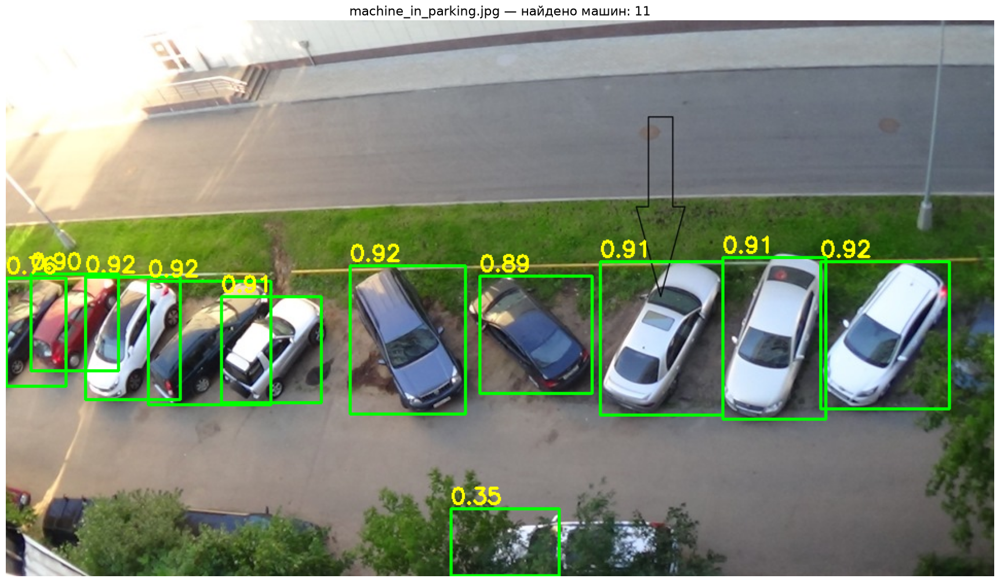

,xmin,ymin,xmax,ymax,conf
0,77.694382,249.152817,169.771912,368.967072,0.923844
1,791.416199,234.992188,916.696411,377.847809,0.919750
2,138.340195,253.380447,257.432892,373.725342,0.918749
3,334.210022,238.849167,446.195862,382.279236,0.916264
4,209.476379,268.179382,306.557800,371.285736,0.914458
5,577.877075,234.164825,696.803833,383.108643,0.914083
6,696.860413,230.400009,796.986389,387.172516,0.913593
7,24.452524,246.246689,109.763680,340.331818,0.903512
8,460.800018,248.043503,569.190063,362.489075,0.886500
9,0.000000,250.532944,58.227695,355.372406,0.761926


In [34]:
MY_IMAGE = '/data/Desktop/ml_10-06/42-CarsObjectDetection/machine_in_parking.jpg'
detect_cars(MY_IMAGE)

In [35]:
sample = pd.read_csv(SAMPLE_PATH)
ID_COL, PRED_COL = sample.columns[:2]
stem2path = {p.stem: p for p in test_imgs}
SUB_CONF = 0.05

preds = []
for sid in sample[ID_COL]:
    img, boxes, scores = predict_sahi(stem2path[str(sid)])
    H, W = img.shape[:2]
    vals = []
    for (x1, y1, x2, y2), s in zip(boxes, scores):
        if s < SUB_CONF:
            continue
        vals += [0, round(float(s), 4), round(float((x1 + x2) / 2 / W), 5), round(float((y1 + y2) / 2 / H), 5),
                 round(float((x2 - x1) / W), 5), round(float((y2 - y1) / H), 5)]
    preds.append('[' + ', '.join(str(v) for v in vals) + ']')

sub = pd.DataFrame({ID_COL: sample[ID_COL], PRED_COL: preds})
sub.to_csv(BASE / 'submission.csv', index=False)
print(sub.shape)
sub.head()

(59, 2)


,id,predictions
0,faedbb2c-GOPR6623,"[0, 0.9315, 0.4135, 0.33866, 0.10902, 0.11045,..."
1,3ee1ee02-GOPR6568,"[0, 0.934, 0.5048, 0.36675, 0.11, 0.0935, 0, 0..."
2,aece3643-GOPR6651,"[0, 0.9287, 0.84804, 0.51885, 0.09441, 0.1386,..."
3,22e8c404-GOPR6769,"[0, 0.942, 0.63342, 0.30236, 0.11354, 0.11606,..."
4,9f18d7ed-GOPR6536,"[0, 0.9121, 0.18446, 0.55548, 0.12212, 0.24931..."


In [36]:
for p in sorted((BASE / 'saved_model').iterdir()):
    print(p.name, round(p.stat().st_size / 1e6, 1), 'MB')

cars_yolo26s_best.pt 20.3 MB
config.json 0.0 MB


In [37]:
import hashlib

def md5(path):
    return hashlib.md5(open(path, 'rb').read()).hexdigest()

print(md5(BEST_PATH))
print(md5(BASE / 'saved_model' / 'cars_yolo26s_best.pt'))

76cd8dbbee9dba90d72282e551a2160b
76cd8dbbee9dba90d72282e551a2160b
